## Data Exploration / Cleaning

In [11]:
import pandas as pd

# ============================
# 1. Load datasets
# ============================
train_df = pd.read_csv(r"C:\Projects_Supervisedlearning\Regression_HousepricePrediction\data\raw\train.csv")
eval_df = pd.read_csv(r"C:\Projects_Supervisedlearning\Regression_HousepricePrediction\data\raw\eval.csv")
holdout_df= pd.read_csv(r"C:\Projects_Supervisedlearning\Regression_HousepricePrediction\data\raw\holdout.csv")
#metros = pd.read_csv("/Users/riadanas/Desktop/housing regression MLE/data/raw/usmetros.csv")

pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.max_rows', None)     # Show all rows

In [12]:
print(train_df.shape)
print(eval_df.shape)

(585244, 39)
(149424, 39)


In [13]:
train_df.head()

,date,median_sale_price,median_list_price,median_ppsf,median_list_ppsf,homes_sold,pending_sales,new_listings,inventory,median_dom,avg_sale_to_list,sold_above_list,off_market_in_two_weeks,city,zipcode,year,bank,bus,hospital,mall,park,restaurant,school,station,supermarket,Total Population,Median Age,Per Capita Income,Total Families Below Poverty,Total Housing Units,Median Rent,Median Home Value,Total Labor Force,Unemployed Population,Total School Age Population,Total School Enrollment,Median Commute Time,price,city_full
0,2012-03-31,46550.0,217450.0,31.813674,110.183666,14.0,23.0,44.0,64.0,59.5,0.943662,0.142857,0.043478,ATL,30002,2012,12.0,2.0,4.0,1.0,60.0,45.0,57.0,4.0,7.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,200773.999557,Atlanta-Sandy Springs-Alpharetta
1,2012-03-31,156500.0,182188.5,119.789171,140.818182,177.0,0.0,260.0,310.0,74.0,0.966860,0.237288,0.423581,CLT,28205,2012,0.0,0.0,6.0,0.0,17.0,0.0,42.0,2.0,0.0,42087.0,32.9,23739.0,41735.0,20816.0,747.0,163000.0,24348.0,2632.0,39826.0,39826.0,20345.0,137474.419588,Charlotte-Concord-Gastonia
2,2012-03-31,179000.0,210000.0,97.687880,103.876898,62.0,100.0,107.0,50.0,42.5,0.979635,0.193548,0.360000,DEN,80021,2012,4.0,2.0,4.0,0.0,100.0,14.0,45.0,0.0,6.0,29760.0,34.1,33485.0,29556.0,13318.0,1099.0,233000.0,19023.0,1253.0,28622.0,28622.0,16400.0,207284.065948,Denver-Aurora-Lakewood
3,2012-03-31,150000.0,193950.0,66.799886,73.878756,141.0,210.0,212.0,129.0,43.0,0.992497,0.326241,0.338095,DEN,80022,2012,0.0,0.0,0.0,0.0,9.0,0.0,27.0,0.0,1.0,41066.0,30.3,20242.0,40821.0,14240.0,874.0,170800.0,20029.0,2133.0,38001.0,38001.0,17057.0,151368.875848,Denver-Aurora-Lakewood
4,2012-03-31,635000.0,785000.0,358.716732,409.102025,69.0,83.0,150.0,123.0,33.5,0.971636,0.130435,0.180723,DC,20815,2012,64.0,1.0,11.0,2.0,238.0,124.0,159.0,12.0,23.0,30152.0,44.7,91791.0,30003.0,14196.0,1801.0,873700.0,16643.0,777.0,29093.0,29093.0,14038.0,861060.378768,DC_Metro


In [14]:
train_df['city_full'].value_counts().head()

city_full
New York-Newark-Jersey City       78020
Chicago-Naperville-Elgin          35344
Los Angeles-Long Beach-Anaheim    33840
Philadelphia-Camden-Wilmington    31396
DC_Metro                          29516
Name: count, dtype: int64

### Map cities to Lat/Long
- The goal is to use Lattitude and longitude instead of cities for our ML models

In [15]:
# ============================
# 2. Fix city name mismatches
# ============================
'''city_mapping = {
    'Las Vegas-Henderson-Paradise': 'Las Vegas-Henderson-North Las Vegas',
    'Denver-Aurora-Lakewood': 'Denver-Aurora-Centennial',
    'Houston-The Woodlands-Sugar Land': 'Houston-Pasadena-The Woodlands',
    'Austin-Round Rock-Georgetown': 'Austin-Round Rock-San Marcos',
    'Miami-Fort Lauderdale-Pompano Beach': 'Miami-Fort Lauderdale-West Palm Beach',
    'San Francisco-Oakland-Berkeley': 'San Francisco-Oakland-Fremont',
    'DC_Metro': 'Washington-Arlington-Alexandria',
    'Atlanta-Sandy Springs-Alpharetta': 'Atlanta-Sandy Springs-Roswell'
}'''

"city_mapping = {\n    'Las Vegas-Henderson-Paradise': 'Las Vegas-Henderson-North Las Vegas',\n    'Denver-Aurora-Lakewood': 'Denver-Aurora-Centennial',\n    'Houston-The Woodlands-Sugar Land': 'Houston-Pasadena-The Woodlands',\n    'Austin-Round Rock-Georgetown': 'Austin-Round Rock-San Marcos',\n    'Miami-Fort Lauderdale-Pompano Beach': 'Miami-Fort Lauderdale-West Palm Beach',\n    'San Francisco-Oakland-Berkeley': 'San Francisco-Oakland-Fremont',\n    'DC_Metro': 'Washington-Arlington-Alexandria',\n    'Atlanta-Sandy Springs-Alpharetta': 'Atlanta-Sandy Springs-Roswell'\n}"

In [16]:
''''def clean_and_merge(df: pd.DataFrame) -> pd.DataFrame:
    """Apply city name fixes, merge lat/lng from metros, drop dup col."""
    df["city_full"] = df["city_full"].replace(city_mapping)
    
    df = df.merge(
        metros[["metro_full", "lat", "lng"]],
        how="left",
        left_on="city_full",
        right_on="metro_full"
    )
    df.drop(columns=["metro_full"], inplace=True)

    # Log any cities that still didn’t match
    missing = df[df["lat"].isnull()]["city_full"].unique()
    if len(missing) > 0:
        print("⚠️ Still missing lat/lng for:", missing)
    else:
        print("✅ All cities matched with metros dataset.")

    return df
'''

'\'def clean_and_merge(df: pd.DataFrame) -> pd.DataFrame:\n    """Apply city name fixes, merge lat/lng from metros, drop dup col."""\n    df["city_full"] = df["city_full"].replace(city_mapping)\n\n    df = df.merge(\n        metros[["metro_full", "lat", "lng"]],\n        how="left",\n        left_on="city_full",\n        right_on="metro_full"\n    )\n    df.drop(columns=["metro_full"], inplace=True)\n\n    # Log any cities that still didn’t match\n    missing = df[df["lat"].isnull()]["city_full"].unique()\n    if len(missing) > 0:\n        print("⚠️ Still missing lat/lng for:", missing)\n    else:\n        print("✅ All cities matched with metros dataset.")\n\n    return df\n'

In [17]:
print(train_df.shape)
print(eval_df.shape)

(585244, 39)
(149424, 39)


In [18]:
# ============================
# 3. Apply cleaning + merge to both train and eval
# ============================
'''train_df = clean_and_merge(train_df)
eval_df = clean_and_merge(eval_df)'''

'train_df = clean_and_merge(train_df)\neval_df = clean_and_merge(eval_df)'

In [19]:
"""from category_encoders import TargetEncoder

target = "median_sale_price"
features = [col for col in train_df.columns if col != target]

city_encoder = TargetEncoder(
    cols=["city_full"],
    handle_unknown="value",
    handle_missing="value"
)

train_df[features] = city_encoder.fit_transform(
    train_df[features],
    train_df[target]
)

eval_df[features] = city_encoder.transform(eval_df[features])
holdout_df[features] = city_encoder.transform(holdout_df[features])"""

'from category_encoders import TargetEncoder\n\ntarget = "median_sale_price"\nfeatures = [col for col in train_df.columns if col != target]\n\ncity_encoder = TargetEncoder(\n    cols=["city_full"],\n    handle_unknown="value",\n    handle_missing="value"\n)\n\ntrain_df[features] = city_encoder.fit_transform(\n    train_df[features],\n    train_df[target]\n)\n\neval_df[features] = city_encoder.transform(eval_df[features])\nholdout_df[features] = city_encoder.transform(holdout_df[features])'

In [20]:
print(train_df.shape)
print(eval_df.shape)
print(holdout_df.shape)

(585244, 39)
(149424, 39)
(149424, 39)


In [21]:
train_df.head()

,date,median_sale_price,median_list_price,median_ppsf,median_list_ppsf,homes_sold,pending_sales,new_listings,inventory,median_dom,avg_sale_to_list,sold_above_list,off_market_in_two_weeks,city,zipcode,year,bank,bus,hospital,mall,park,restaurant,school,station,supermarket,Total Population,Median Age,Per Capita Income,Total Families Below Poverty,Total Housing Units,Median Rent,Median Home Value,Total Labor Force,Unemployed Population,Total School Age Population,Total School Enrollment,Median Commute Time,price,city_full
0,2012-03-31,46550.0,217450.0,31.813674,110.183666,14.0,23.0,44.0,64.0,59.5,0.943662,0.142857,0.043478,ATL,30002,2012,12.0,2.0,4.0,1.0,60.0,45.0,57.0,4.0,7.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,200773.999557,Atlanta-Sandy Springs-Alpharetta
1,2012-03-31,156500.0,182188.5,119.789171,140.818182,177.0,0.0,260.0,310.0,74.0,0.966860,0.237288,0.423581,CLT,28205,2012,0.0,0.0,6.0,0.0,17.0,0.0,42.0,2.0,0.0,42087.0,32.9,23739.0,41735.0,20816.0,747.0,163000.0,24348.0,2632.0,39826.0,39826.0,20345.0,137474.419588,Charlotte-Concord-Gastonia
2,2012-03-31,179000.0,210000.0,97.687880,103.876898,62.0,100.0,107.0,50.0,42.5,0.979635,0.193548,0.360000,DEN,80021,2012,4.0,2.0,4.0,0.0,100.0,14.0,45.0,0.0,6.0,29760.0,34.1,33485.0,29556.0,13318.0,1099.0,233000.0,19023.0,1253.0,28622.0,28622.0,16400.0,207284.065948,Denver-Aurora-Lakewood
3,2012-03-31,150000.0,193950.0,66.799886,73.878756,141.0,210.0,212.0,129.0,43.0,0.992497,0.326241,0.338095,DEN,80022,2012,0.0,0.0,0.0,0.0,9.0,0.0,27.0,0.0,1.0,41066.0,30.3,20242.0,40821.0,14240.0,874.0,170800.0,20029.0,2133.0,38001.0,38001.0,17057.0,151368.875848,Denver-Aurora-Lakewood
4,2012-03-31,635000.0,785000.0,358.716732,409.102025,69.0,83.0,150.0,123.0,33.5,0.971636,0.130435,0.180723,DC,20815,2012,64.0,1.0,11.0,2.0,238.0,124.0,159.0,12.0,23.0,30152.0,44.7,91791.0,30003.0,14196.0,1801.0,873700.0,16643.0,777.0,29093.0,29093.0,14038.0,861060.378768,DC_Metro


## clean Duplicates

In [22]:
print(train_df.shape)


duplicated_rows = train_df[train_df.duplicated()].shape[0]
print("duplicated_rows:", duplicated_rows)

duplicated_rows = train_df[train_df.duplicated(subset=train_df.columns.difference(['date', 'year']))].shape[0]
print("duplicated_rows excluding date column:", duplicated_rows)

(585244, 39)
duplicated_rows: 0
duplicated_rows excluding date column: 6321


In [23]:
# Delete duplicates
train_df = train_df.drop_duplicates(subset=train_df.columns.difference(['date', 'year']), keep=False)

print(train_df.shape)

duplicated_rows = train_df[train_df.duplicated()].shape[0]
print("duplicated_rows:", duplicated_rows)

duplicated_rows = train_df[train_df.duplicated(subset=train_df.columns.difference(['date', 'year']))].shape[0]
print("duplicated_rows excluding date column:", duplicated_rows)

(576860, 39)
duplicated_rows: 0
duplicated_rows excluding date column: 0


In [24]:
print(eval_df.shape)


duplicated_rows = eval_df[eval_df.duplicated()].shape[0]
print("duplicated_rows:", duplicated_rows)

duplicated_rows = eval_df[eval_df.duplicated(subset=eval_df.columns.difference(['date', 'year']))].shape[0]
print("duplicated_rows excluding date column:", duplicated_rows)

(149424, 39)
duplicated_rows: 0
duplicated_rows excluding date column: 726


In [25]:
# Delete duplicates
eval_df = eval_df.drop_duplicates(subset=eval_df.columns.difference(['date', 'year']), keep=False)

print(eval_df.shape)


duplicated_rows = eval_df[eval_df.duplicated()].shape[0]
print("duplicated_rows:", duplicated_rows)

duplicated_rows = eval_df[eval_df.duplicated(subset=eval_df.columns.difference(['date', 'year']))].shape[0]
print("duplicated_rows excluding date column:", duplicated_rows)

(148449, 39)
duplicated_rows: 0
duplicated_rows excluding date column: 0


In [26]:
# Delete duplicate rows, ignoring the date and year columns
holdout_df = holdout_df.drop_duplicates(
    subset=holdout_df.columns.difference(["date", "year"]),
    keep=False
)

print(holdout_df.shape)

duplicated_rows = holdout_df[holdout_df.duplicated()].shape[0]
print("duplicated_rows:", duplicated_rows)

duplicated_rows = holdout_df[
    holdout_df.duplicated(
        subset=holdout_df.columns.difference(["date", "year"])
    )
].shape[0]
print("duplicated_rows excluding date column:", duplicated_rows)

(148945, 39)
duplicated_rows: 0
duplicated_rows excluding date column: 0


## clean outliers

In [27]:
train_df['median_list_price'].describe()

count    5.768600e+05
mean     3.734342e+05
std      2.318935e+06
min      0.000000e+00
25%      1.724500e+05
50%      2.760000e+05
75%      4.390000e+05
max      1.000000e+09
Name: median_list_price, dtype: float64

In [28]:
import sys
print(sys.executable)

import nbformat
print(nbformat.__version__)

c:\Projects_Supervisedlearning\Regression_HousepricePrediction\.venv\Scripts\python.exe
5.11.1


In [29]:
import plotly.express as px

fig = px.violin(train_df, y="median_list_price", box=True, hover_name="median_list_price")
fig.update_layout(title="Violin Plot of Median List Price")
fig.show()

In [30]:
top_1_percent = train_df.nlargest(int(0.01 * len(train_df)), 'median_list_price')
print(top_1_percent.shape)
top_1_percent.head(10)

(5768, 39)


,date,median_sale_price,median_list_price,median_ppsf,median_list_ppsf,homes_sold,pending_sales,new_listings,inventory,median_dom,avg_sale_to_list,sold_above_list,off_market_in_two_weeks,city,zipcode,year,bank,bus,hospital,mall,park,restaurant,school,station,supermarket,Total Population,Median Age,Per Capita Income,Total Families Below Poverty,Total Housing Units,Median Rent,Median Home Value,Total Labor Force,Unemployed Population,Total School Age Population,Total School Enrollment,Median Commute Time,price,city_full
267955,2015-10-31,439000.0,999999999.0,218.867925,236.391156,243.0,269.0,671.0,259.0,46.0,0.980975,0.160494,0.130112,DC,20878,2015,9.0,0.0,4.0,1.0,110.0,59.0,50.0,2.0,11.0,63855.0,38.1,52955.0,63757.0,23514.0,1677.0,535500.0,36595.0,1960.0,61237.0,61237.0,32125.0,5.143890e+05,DC_Metro
279579,2015-11-30,425000.0,999999999.0,220.055710,236.634569,241.0,284.0,616.0,196.0,47.0,0.979123,0.132780,0.133803,DC,20878,2015,9.0,0.0,4.0,1.0,110.0,59.0,50.0,2.0,11.0,63855.0,38.1,52955.0,63757.0,23514.0,1677.0,535500.0,36595.0,1960.0,61237.0,61237.0,32125.0,5.148844e+05,DC_Metro
281546,2015-12-31,439444.0,999999999.0,217.479377,231.798505,254.0,255.0,536.0,136.0,53.0,0.976354,0.137795,0.109804,DC,20878,2015,9.0,0.0,4.0,1.0,110.0,59.0,50.0,2.0,11.0,63855.0,38.1,52955.0,63757.0,23514.0,1677.0,535500.0,36595.0,1960.0,61237.0,61237.0,32125.0,5.152060e+05,DC_Metro
314434,2016-05-31,270000.0,50449949.5,232.758621,4156.568441,1.0,1.0,2.0,2.0,264.0,1.000000,0.000000,0.000000,DC,20838,2016,0.0,0.0,0.0,0.0,11.0,1.0,4.0,2.0,0.0,247.0,49.6,61165.0,243.0,93.0,1507.0,607100.0,135.0,0.0,239.0,239.0,122.0,6.739973e+05,DC_Metro
319852,2016-06-30,415000.0,50449949.5,257.508343,4156.568441,2.0,2.0,2.0,2.0,324.5,1.000447,0.500000,0.000000,DC,20838,2016,0.0,0.0,0.0,0.0,11.0,1.0,4.0,2.0,0.0,247.0,49.6,61165.0,243.0,93.0,1507.0,607100.0,135.0,0.0,239.0,239.0,122.0,6.739973e+05,DC_Metro
326747,2016-07-31,270000.0,50449949.5,232.758621,4156.568441,3.0,3.0,2.0,2.0,264.0,0.973591,0.333333,0.000000,DC,20838,2016,0.0,0.0,0.0,0.0,11.0,1.0,4.0,2.0,0.0,247.0,49.6,61165.0,243.0,93.0,1507.0,607100.0,135.0,0.0,239.0,239.0,122.0,6.739973e+05,DC_Metro
280609,2015-12-31,830000.0,27800000.0,459.833795,3677.735150,3.0,3.0,1.0,22.0,235.0,0.842625,0.000000,0.000000,NY,7620,2015,10.0,0.0,10.0,0.0,46.0,18.0,69.0,3.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.366853e+06,New York-Newark-Jersey City
305027,2016-03-31,4050000.0,19990000.0,613.636364,2815.492958,2.0,2.0,1.0,4.0,183.0,0.942957,0.000000,0.000000,NY,11962,2016,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0,415.0,46.9,99829.0,415.0,838.0,1440.0,2000001.0,167.0,0.0,415.0,415.0,128.0,3.632048e+06,New York-Newark-Jersey City
306514,2016-04-30,4050000.0,19990000.0,613.636364,2815.492958,2.0,2.0,1.0,4.0,183.0,0.942957,0.000000,0.000000,NY,11962,2016,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0,415.0,46.9,99829.0,415.0,838.0,1440.0,2000001.0,167.0,0.0,415.0,415.0,128.0,3.663367e+06,New York-Newark-Jersey City
313240,2016-05-31,4050000.0,19990000.0,613.636364,2815.492958,2.0,2.0,1.0,4.0,183.0,0.942957,0.000000,0.000000,NY,11962,2016,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0,415.0,46.9,99829.0,415.0,838.0,1440.0,2000001.0,167.0,0.0,415.0,415.0,128.0,3.678078e+06,New York-Newark-Jersey City


In [31]:
top_1_percent = train_df.nlargest(int(0.01 * len(train_df)), 'median_list_price')
print(top_1_percent['median_list_price'].value_counts().sort_index(ascending=False))

median_list_price
999999999.0      3
50449949.5       3
27800000.0       1
19990000.0      38
15849000.0       1
15624500.0       3
15500000.0       1
13995000.0       1
13100000.0       2
12772000.0       1
12500000.0       5
11900000.0       1
11495000.0       1
10747500.0       1
10692000.0      16
10000000.0       3
9999998.0        1
9934000.0        2
9697500.0        3
9547500.0        1
9394000.0        1
9350000.0        1
9100000.0        1
8900000.0        1
8793944.0        5
8750000.0        3
8700000.0        2
8500000.0        1
8495000.0        1
8142500.0        1
8000000.0        3
7995000.0        1
7988000.0        1
7947500.0        1
7941500.0        1
7750000.0        4
7695000.0        2
7522500.0        1
7495000.0        1
7472500.0        1
7450000.0        1
7442500.0        2
7424000.0        1
7374950.0        1
7300000.0        3
7299500.0        1
7245000.0        1
7199000.0        3
7000000.0        1
6999500.0        1
6995000.0       31
6945000.0    

- Investigate if median_list_price outliers are independent in distinct regions (for example if DC has different median_list_price)
- Drop outliers to keep things realistic and clean

In [32]:
# Clean outliers above 19M in both train and eval
train_df = train_df[train_df['median_list_price'] <= 19_000_000].copy()
eval_df = eval_df[eval_df['median_list_price'] <= 19_000_000].copy()
# Remove rows where median_list_price is above 19 million
holdout_df = holdout_df[
    holdout_df["median_list_price"] <= 19_000_000
].copy()

In [33]:
import plotly.express as px

fig = px.violin(train_df, y="median_list_price", box=True, hover_name="median_list_price")
fig.update_layout(title="Violin Plot of Median List Price")
fig.show()

In [34]:
top_1_percent = train_df.nlargest(int(0.01 * len(train_df)), 'median_list_price')
print(top_1_percent['median_list_price'].value_counts().sort_index(ascending=False))

median_list_price
15849000.0      1
15624500.0      3
15500000.0      1
13995000.0      1
13100000.0      2
12772000.0      1
12500000.0      5
11900000.0      1
11495000.0      1
10747500.0      1
10692000.0     16
10000000.0      3
9999998.0       1
9934000.0       2
9697500.0       3
9547500.0       1
9394000.0       1
9350000.0       1
9100000.0       1
8900000.0       1
8793944.0       5
8750000.0       3
8700000.0       2
8500000.0       1
8495000.0       1
8142500.0       1
8000000.0       3
7995000.0       1
7988000.0       1
7947500.0       1
7941500.0       1
7750000.0       4
7695000.0       2
7522500.0       1
7495000.0       1
7472500.0       1
7450000.0       1
7442500.0       2
7424000.0       1
7374950.0       1
7300000.0       3
7299500.0       1
7245000.0       1
7199000.0       3
7000000.0       1
6999500.0       1
6995000.0      31
6945000.0       1
6847500.0       1
6844000.0       2
6822000.0       1
6720000.0       1
6700000.0       1
6665000.0       1
6650000.0 

In [35]:
# ============================
# 4. Save cleaned datasets
# ============================
train_df.to_csv(r"C:\Projects_Supervisedlearning\Regression_HousepricePrediction\data\processed/cleaning_train.csv", index=False)
eval_df.to_csv(r"C:\Projects_Supervisedlearning\Regression_HousepricePrediction\data\processed/cleaning_eval.csv", index=False)
holdout_df.to_csv(r"C:\Projects_Supervisedlearning\Regression_HousepricePrediction\data\processed/cleaning_holdout.csv",index=False)
print("✅ Cleaning complete.")

✅ Cleaning complete.


## Housing prices exploration

In [36]:
df = train_df

C:\Users\dhine\AppData\Local\Temp\ipykernel_3492\522431743.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


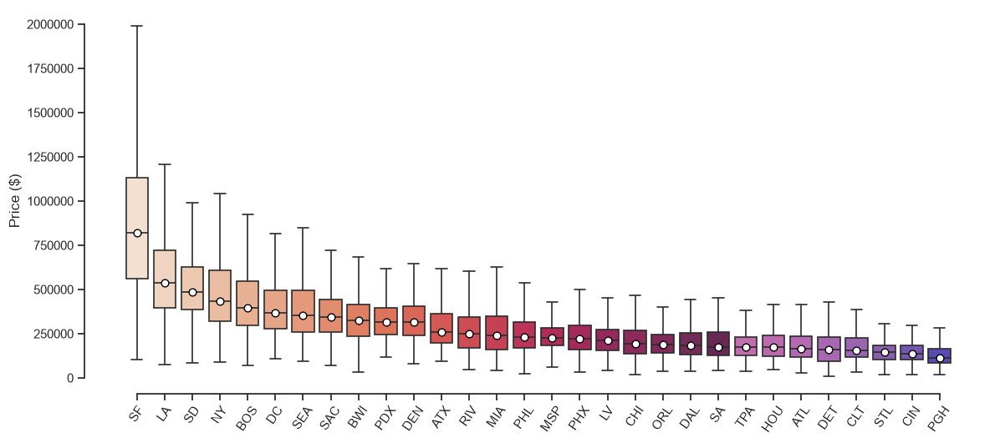

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt
import colorsys
sns.set_theme(style="whitegrid")           

# Boxplot of house prices for the cities
#, ordered by median price.

top_cities = df["city"].value_counts().head(30).index.tolist()
df_city    = df[df["city"].isin(top_cities)]
city_order = (
    df_city.groupby("city")["price"]
           .median()
           .sort_values(ascending=False)
           .index
)

base = sns.color_palette("rocket_r", len(city_order))

def lighten(color, amt=.4):
    h, l, s = colorsys.rgb_to_hls(*color)
    return colorsys.hls_to_rgb(h, min(1, l + amt*(1-l)), s)
palette = [
    lighten(c, .45) if i >= len(base) - 8 else c
    for i, c in enumerate(base)
]

sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    x="city", y="price", data=df_city,
    order=city_order, palette=palette,
    showfliers=False, linewidth=1.2, ax=ax
)

medians = df_city.groupby("city")["price"].median().loc[city_order]
for tick, median in enumerate(medians):
    ax.scatter(tick, median, color="white", edgecolor="black", zorder=5, s=40)

ax.set_xlabel("")
ax.set_ylabel("Price ($)")
ax.tick_params(axis="x", rotation=55)
sns.despine(trim=True)
ax.grid(False)
ax.ticklabel_format(axis="y", style="plain")

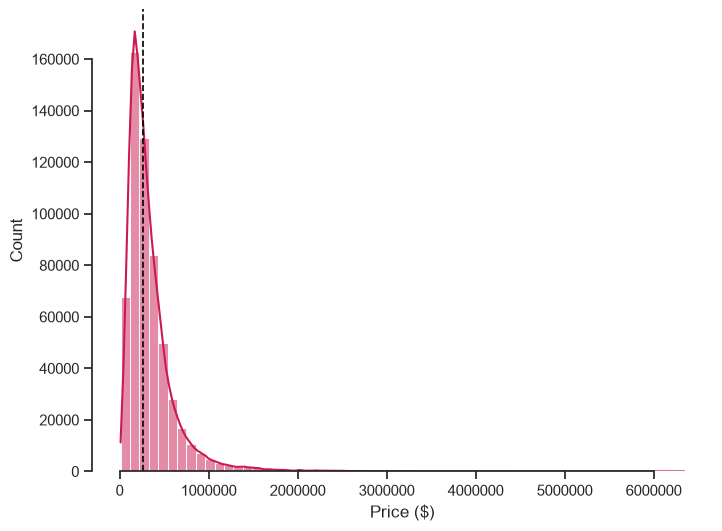

In [38]:
# Distribution of house prices across the dataset 

sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(df["price"].dropna(), bins=60, kde=True, color=sns.color_palette("rocket_r", 1)[0], ax=ax)
median_price = df["price"].median()
ax.axvline(median_price, ls="--", lw=1.2, color="black")
ax.set_xlabel("Price ($)")
ax.set_ylabel("Count")
sns.despine(trim=True)
ax.grid(False)
ax.ticklabel_format(axis="x", style="plain")
plt.show()